# Tutorial 1, Problem 2. 

## Ethylene production using an isothermal PFR

- Description: Programm to calculate the volume of a PFR reactor for an irreversible reaction 
- Author: Dr Carlos Avendano
- Last version:  October 2026

In [1]:
# Required Libraries
import numpy as np                     # Library for array manupulations
import matplotlib.pyplot as plt        # Array for plotting
from scipy.integrate import solve_ivp  # ODE solver (Runge-Kutta)

## Define the plug flow reactor model

In [2]:
def pfr_model(volume,z, temp, press):
    '''
        This function defines the model of a plug flow reactor. 
        It takes in volume, the current molar flow rates of the 
        three species A, B, and C. The function returns the rates
        of change of the three species (dF_A/dV, dF_B/dV, dF_C/dV) as 
        a list.
        The model also receives the temperature, and the pressure
        as arguments.
    '''

    # Unwrap the molar flow rate
    F_A = z[0]
    F_B = z[1]
    F_C = z[2]

    # Compute the total molar flow rate
    F_tot = F_A + F_B + F_C

    # Ideal gas constant
    R_ideal = 8.314

    # Arrenhius equation to obtain the rate constant
    k = 0.072*np.exp(343.3e3/R_ideal*(1/1000-1/temp))

    # Compute the total initial concentration 
    C_tot_0 = press/(R_ideal*temp)

    # Compute the concentration of A
    CA = C_tot_0*F_A/F_tot

    # Rate constants
    r_A = -k*CA
    r_B = -r_A
    r_C = -r_A

    # Mole balances
    dFA_dV = r_A
    dFB_dV = r_B
    dFC_dV = r_C

    # Return the system of differential equations
    return [dFA_dV,dFB_dV,dFC_dV]


## Solving the system of differential equations

In [3]:
# Define the temperature (Kelvin)
temp = 1100

# Define the pressure (Pa)
press = 608e3

''' Define volume span (in this case from 0 to 3 m^3). 
    Please note that the volume span can be changed to any 
    value you want but you need to ensure that is large enough 
    to reach a conversion of A of at least 0.8, since this is 
    asked in the problem
'''

max_vol = 3
volume_span = (0,max_vol)

''' Construct array to evaluate the solutions. Here, 
    we use 500 time steps but you can change it to any 
    number you want: the more time steps, the higher 
    the resolution of the solution. 
'''

# Define array for integration of the volume
vol_steps = 500
volume_array = np.linspace(0,max_vol,vol_steps)

# Initial conditions for the molar flow rates 
F_0 = [192.5,0,0]

# Solve mass balance by integrating the differential equation
solution = solve_ivp(pfr_model,t_span=volume_span,y0=F_0,t_eval=volume_array,args=(temp,press))

# From the solution, calculate the total molar flow rates along the reactor
F_tot = solution.y[0,:] + solution.y[1,:] + solution.y[2,:]

# Compute the conversion of ethane (A)
conversion = 1-solution.y[0,:]/F_0[0]

# Compute the mole fraction in the gas phase
y_fraction = solution.y/F_tot

## Tabulate the data to extract numbers if needed

In [4]:
print('    {0:12} {1:12} {2:14} {3:12} {4:12} {5:12}'.format('Volume','Conversion','F_A', 'F_B', 'F_C', 'F_tot'))
for i in range(vol_steps):
    print('{0:12.6f} {1:12.6f}  {2:12.6f}  {3:12.6f}  {4:12.6f}  {5:12.6f}'.format(
        solution.t[i],
        conversion[i], 
        solution.y[0,i],
        solution.y[1,i],
        solution.y[2,i],
        F_tot[i]))


    Volume       Conversion   F_A            F_B          F_C          F_tot       
    0.000000     0.000000    192.500000      0.000000      0.000000    192.500000
    0.006012     0.006340    191.279460      1.220540      1.220540    193.720540
    0.012024     0.012602    190.074204      2.425796      2.425796    194.925796
    0.018036     0.018785    188.883857      3.616143      3.616143    196.116143
    0.024048     0.024893    187.708057      4.791943      4.791943    197.291943
    0.030060     0.030927    186.546457      5.953543      5.953543    198.453543
    0.036072     0.036890    185.398721      7.101279      7.101279    199.601279
    0.042084     0.042782    184.264467      8.235533      8.235533    200.735533
    0.048096     0.048607    183.143167      9.356833      9.356833    201.856833
    0.054108     0.054366    182.034562     10.465438     10.465438    202.965438
    0.060120     0.060060    180.938425     11.561575     11.561575    204.061575
    0.066132  

## Finding the volume for the target conversion

There are several ways to determine the reactor volume required to achieve the target conversion.

For example, if you have calculated the solution using a sufficiently fine grid, you can simply inspect the results and identify the volume corresponding to a conversion of 0.8.

Another approach is as follows:

* Define the target conversion as 0.8.

* Create a new array containing the absolute difference between each calculated conversion and the target conversion.

* Use numpy.argmin() to find the position where this difference is smallest. This identifies the calculated conversion that is closest to the target value.

* Use the same position in the volume array to obtain the corresponding reactor volume.

* Use the same position for any other properties

In [5]:
# Target conversion
x_target = 0.8

# Create array containing the absolute difference between conversion and target conversion
difference = np.abs(conversion - x_target)

# Find the position of the minimum
index_min = np.argmin(difference)

# Evalauate properties at the target conversion
volume_actual = solution.t[index_min]
x_actual = conversion[index_min]
FA_actual = solution.y[0,index_min]
FB_actual = solution.y[1,index_min]
FC_actual = solution.y[2,index_min]
yA_actual = y_fraction[0,index_min]
yB_actual = y_fraction[1,index_min]
yC_actual = y_fraction[2,index_min]


print('At the conversion  X={0:7.6f}, the properties are:'.format(x_actual))
print('      - vol = {0:7.6f}'.format(volume_actual))
print('      - F_A = {0:7.6f}'.format(FA_actual))
print('      - F_B = {0:7.6f}'.format(FB_actual))
print('      - F_C = {0:7.6f}'.format(FC_actual))
print('      - y_A = {0:7.6f}'.format(yA_actual))
print('      - y_B = {0:7.6f}'.format(yB_actual))
print('      - y_C = {0:7.6f}'.format(yC_actual))

At the conversion  X=0.799839, the properties are:
      - vol = 2.278557
      - F_A = 38.530984
      - F_B = 153.969016
      - F_C = 153.969016
      - y_A = 0.111210
      - y_B = 0.444395
      - y_C = 0.444395


## Plotting the results

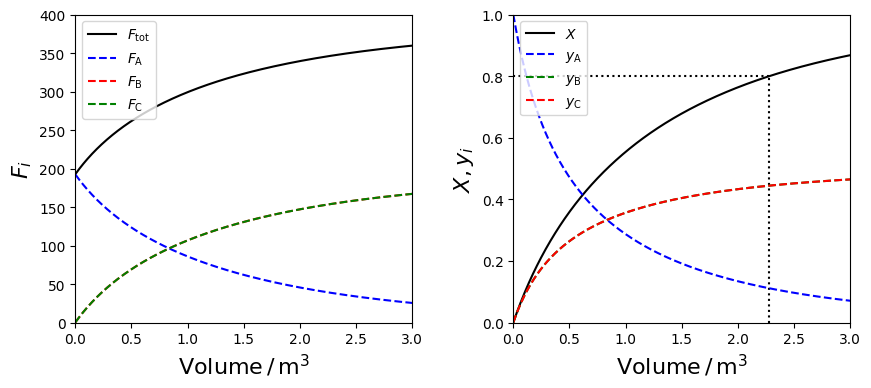

In [6]:
# Create a plot object. The size is in inches
fig=plt.figure(figsize=(10,4))

# Create two subplots in the figure. 
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)


plt.subplots_adjust(wspace=0.3,hspace=0) # This adjust the spacing between plots

# Plot the molar flow rates
ax1.plot(solution.t,F_tot, '-k',label=r'$F_\mathrm{tot}$')
ax1.plot(solution.t,solution.y[0], '--b',label=r'$F_\mathrm{A}$')
ax1.plot(solution.t,solution.y[1], '--r',label=r'$F_\mathrm{B}$')
ax1.plot(solution.t,solution.y[2], '--g',label=r'$F_\mathrm{C}$')
ax1.set_xlabel(r'$\mathrm{Volume}\,/\,{\rm m^3}$',size=16)
ax1.set_ylabel(r'$F_i$',size=16)
ax1.set_xlim([0,3])
ax1.set_ylim([0,400])
ax1.legend()


# Plot conversion
ax2.plot(solution.t,conversion,'-k',label=r'$X$')
# Indicate the reactor volume to achieve the target conversion
ax2.plot([volume_actual,volume_actual],[0,x_target],':k')
ax2.plot([0,volume_actual],[x_actual,x_actual],':k')
# Plot the mole fractions of A, B, and C
ax2.plot(solution.t,y_fraction[0,:],'--b',label=r'$y_\mathrm{A}$')
ax2.plot(solution.t,y_fraction[1,:],'--g',label=r'$y_\mathrm{B}$')
ax2.plot(solution.t,y_fraction[2,:],'--r',label=r'$y_\mathrm{C}$')
ax2.set_xlabel(r'$\mathrm{Volume}\,/\,{\rm m^3}$',size=16)
ax2.set_ylabel(r'$X,y_i$',size=16)
ax2.set_xlim([0,3])
ax2.set_ylim([0,1])
ax2.legend()


# Save figure 
plt.savefig("ethylene.pdf", bbox_inches='tight')
# Display figure
plt.show()